# Phase 3B Steps 9–10 — Effect Sizes and Multiple Testing

This independent notebook consolidates the registered exploratory hypotheses from Notebooks 08, 11, 12, and 13. It recomputes the established tests and effect sizes from only the configured development split, then applies pre-declared family-level multiplicity corrections. It does not repeat distribution diagnostics, simulations, post-hoc plots, feature selection, multicollinearity analysis, or modelling.

All questions were informed by EDA on these same records. Adjusted significance improves error control within this exploratory analysis; it is not independent confirmation or causal evidence.

## 1. Independent, leakage-safe setup

The project root is detected from marker files and configuration is loaded through the existing utility. The input is asserted to be exactly `data/processed/development.parquet`; held-out test and complete validated data are never read.

In [1]:
# ruff: noqa: E501
import hashlib
import importlib.metadata as metadata
import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "params.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from retention.analysis.association import cramers_v  # noqa: E402
from retention.utils.config import load_config  # noqa: E402

config = load_config(PROJECT_ROOT / "params.yaml")
configured_development_path = Path(config["data"]["development_path"])
assert configured_development_path == Path("data/processed/development.parquet")
development_path = (PROJECT_ROOT / configured_development_path).resolve()
assert development_path.is_file()

print(f"Project root: {PROJECT_ROOT}")
print(f"Input: {configured_development_path}")
print(f"Python: {sys.version.split()[0]} ({sys.executable})")
for package in ["pandas", "numpy", "scipy", "matplotlib", "pyarrow"]:
    print(f"{package}: {metadata.version(package)}")

Project root: /Users/harshagarwal/Projects/ChurnRatePredictor
Input: data/processed/development.parquet
Python: 3.11.14 (/Users/harshagarwal/Projects/ChurnRatePredictor/.venv/bin/python)
pandas: 2.3.3
numpy: 2.4.6
scipy: 1.17.1
matplotlib: 3.11.2
pyarrow: 26.0.1


In [2]:
# ruff: noqa: E501
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda value: f"{value:,.8g}")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.labelsize": 11})

random_state = int(config["project"]["random_state"])
target_column = config["data"]["target_column"]
source_sha256_before = hashlib.sha256(development_path.read_bytes()).hexdigest()
df = pd.read_parquet(development_path)
alpha = 0.05
q = 0.05
smallest_positive = np.nextafter(0.0, 1.0)

assert df.shape == (5_634, 21)
assert set(df[target_column].unique()) == {"No", "Yes"}
print(f"Development data: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Random state preserved: {random_state}; alpha={alpha}; FDR q={q}")
print(f"Development SHA-256: {source_sha256_before}")

Development data: 5,634 rows × 21 columns
Random state preserved: 42; alpha=0.05; FDR q=0.05
Development SHA-256: 28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13


## 2. Pre-declared hypothesis families and correction procedures

Testing many true null hypotheses at level $\alpha$ increases the chance of at least one false positive. The **family-wise error rate (FWER)** is the probability of one or more false rejections in a family. The **false discovery rate (FDR)** is the expected false-discovery proportion among rejected hypotheses (defined as zero when none are rejected). Raw p-values describe one test; adjusted p-values incorporate the number and ordering of tests in a declared family.

Families are defined by scientific role before seeing corrected decisions:

1. **Primary feature–churn family (13):** three Welch numerical tests plus ten categorical Pearson chi-square tests. This is the principal exploratory family.
2. **Primary predictor-dependency family (3):** three Welch ANOVA omnibus tests.
3. **Complementary numerical-rank family (3):** three Mann–Whitney tests.
4. **Complementary multiple-group-rank family (3):** three Kruskal–Wallis tests.

Games–Howell pairwise results are not re-created or included: Notebook 13 already adjusts within each post-hoc family. Diagnostics and simulations are not research hypotheses. Families are not split to obtain favourable decisions.

**Benjamini–Hochberg (BH)** orders p-values and controls FDR under independence and under common forms of positive dependence. Several telecom predictors are structurally related, so that guarantee is an assumption rather than a fact; BH remains the primary exploratory procedure at $q=.05$, with **Holm** as a conservative FWER sensitivity analysis at $\alpha=.05$. Holm sequentially compares ordered p-values with $\alpha/(m-i+1)$ and is valid under arbitrary dependence. **Bonferroni** controls FWER by comparing every p-value with $\alpha/m$; it is simple but usually more conservative than Holm, so implementing it would be redundant here.

## 3. Validated correction implementations and numerical stability

Corrections use full-precision numeric p-values, never formatted strings. For finite test statistics, a mathematically nonzero tail can underflow in floating-point arithmetic. Any computed zero is therefore labelled as underflow and conservatively replaced by the smallest positive IEEE-754 `float64` value only for adjustment. This is a numerical upper bound at machine resolution, not a claim that the probability equals zero.

For ordered raw p-values $p_{(i)}$, BH uses $\min_{j\ge i}(mp_{(j)}/j)$ and Holm uses the cumulative maximum of $(m-i+1)p_{(i)}$, both clipped to $[0,1]$.

In [3]:
# ruff: noqa: E501
def adjustment_ready(p_values):
    values = np.asarray(p_values, dtype=float)
    if values.ndim != 1 or not np.isfinite(values).all() or ((values < 0) | (values > 1)).any():
        raise ValueError("p-values must be a finite one-dimensional array in [0, 1].")
    return np.where(values == 0.0, smallest_positive, values)


def benjamini_hochberg(p_values):
    values = adjustment_ready(p_values)
    m = len(values)
    order = np.argsort(values, kind="mergesort")
    ranked = values[order]
    adjusted_ranked = np.minimum.accumulate((ranked * m / np.arange(1, m + 1))[::-1])[::-1]
    adjusted = np.empty(m, dtype=float)
    adjusted[order] = np.clip(adjusted_ranked, 0.0, 1.0)
    return adjusted


def holm(p_values):
    values = adjustment_ready(p_values)
    m = len(values)
    order = np.argsort(values, kind="mergesort")
    ranked = values[order]
    adjusted_ranked = np.maximum.accumulate(ranked * np.arange(m, 0, -1))
    adjusted = np.empty(m, dtype=float)
    adjusted[order] = np.clip(adjusted_ranked, 0.0, 1.0)
    return adjusted


def assert_sorted_monotonic(raw, adjusted):
    order = np.argsort(raw, kind="mergesort")
    assert np.all(np.diff(np.asarray(adjusted)[order]) >= -1e-15)


example = np.array([0.01, 0.04, 0.03, 0.002])
expected_bh = np.array([0.02, 0.04, 0.04, 0.008])
expected_holm = np.array([0.03, 0.06, 0.06, 0.008])
assert np.allclose(benjamini_hochberg(example), expected_bh)
assert np.allclose(holm(example), expected_holm)
for method in [benjamini_hochberg, holm]:
    adjusted_example = method(example)
    assert np.asarray(adjusted_example).shape == example.shape
    assert ((0 <= adjusted_example) & (adjusted_example <= 1)).all()
    assert_sorted_monotonic(example, adjusted_example)
assert benjamini_hochberg([0.0, 1.0]).min() > 0
print("BH and Holm passed analytic-example, monotonicity, shape, and bound checks.")

BH and Holm passed analytic-example, monotonicity, shape, and bound checks.


## 4. Reproduce numerical feature–churn results

For HYP-01–03, the comparison direction remains **churned minus retained**. Welch's test targets the mean difference and reports its 95% interval. Cohen's $d$ standardizes that difference by the pooled sample standard deviation; pooling is descriptive and does not impose equal variance on Welch's test. The complementary Mann–Whitney analysis targets relative ordering, with tie-aware Cliff's $\delta=2U/(n_Yn_N)-1$. Different effect measures remain on their own scales and are not combined into a feature score.

In [4]:
# ruff: noqa: E501
numerical_specs = {
    "HYP-01": {"variable": "tenure", "question": "Does tenure differ by churn outcome?"},
    "HYP-02": {"variable": "MonthlyCharges", "question": "Do MonthlyCharges differ by churn outcome?"},
    "HYP-03": {"variable": "TotalCharges", "question": "Do TotalCharges differ by churn outcome?"},
}


def welch_two_group(churned, retained, confidence=0.95):
    y = np.asarray(churned, float); n = np.asarray(retained, float)
    ny, nn = len(y), len(n); my, mn = y.mean(), n.mean(); vy, vn = y.var(ddof=1), n.var(ddof=1)
    difference = my - mn; se = np.sqrt(vy / ny + vn / nn)
    degrees_freedom = (vy / ny + vn / nn) ** 2 / ((vy / ny) ** 2 / (ny - 1) + (vn / nn) ** 2 / (nn - 1))
    statistic = difference / se
    p_value = 2 * stats.t.sf(abs(statistic), degrees_freedom)
    critical = stats.t.ppf((1 + confidence) / 2, degrees_freedom)
    pooled_sd = np.sqrt(((ny - 1) * vy + (nn - 1) * vn) / (ny + nn - 2))
    return statistic, degrees_freedom, p_value, difference, difference - critical * se, difference + critical * se, difference / pooled_sd


def mann_whitney(churned, retained):
    y = np.asarray(churned, float); n = np.asarray(retained, float)
    result = stats.mannwhitneyu(y, n, alternative="two-sided", method="asymptotic", use_continuity=True)
    superiority = result.statistic / (len(y) * len(n))
    return result.statistic, result.pvalue, 2 * superiority - 1


numerical_rows = []
for hypothesis_id, spec in numerical_specs.items():
    churned = df.loc[df[target_column].eq("Yes"), spec["variable"]].to_numpy(float)
    retained = df.loc[df[target_column].eq("No"), spec["variable"]].to_numpy(float)
    statistic, degrees_freedom, p_value, difference, ci_lower, ci_upper, cohens_d = welch_two_group(churned, retained)
    u_statistic, rank_p, cliffs_delta = mann_whitney(churned, retained)
    numerical_rows.extend([
        {"hypothesis_id": hypothesis_id, "research_question": spec["question"], "statistical_test": "Welch independent t-test", "estimand": "Mean difference (churned − retained)", "designation": "Primary", "test_statistic": statistic, "degrees_of_freedom": degrees_freedom, "raw_p_value": p_value, "effect_size": cohens_d, "effect_size_measure": "Cohen's d (churned − retained)", "confidence_interval": f"[{ci_lower:.8g}, {ci_upper:.8g}]", "multiple_testing_family": "Primary feature–churn"},
        {"hypothesis_id": hypothesis_id, "research_question": spec["question"], "statistical_test": "Mann–Whitney U (tie-corrected asymptotic)", "estimand": "Relative ordering: P(Y>N)+0.5P(Y=N)", "designation": "Complementary", "test_statistic": u_statistic, "degrees_of_freedom": np.nan, "raw_p_value": rank_p, "effect_size": cliffs_delta, "effect_size_measure": "Cliff's delta (churned − retained)", "confidence_interval": "Not estimated", "multiple_testing_family": "Complementary numerical ranks"},
    ])

numerical_results = pd.DataFrame(numerical_rows)
display(numerical_results)

,hypothesis_id,research_question,statistical_test,estimand,designation,test_statistic,degrees_of_freedom,raw_p_value,effect_size,effect_size_measure,confidence_interval,multiple_testing_family
0,HYP-01,Does tenure differ by churn outcome?,Welch independent t-test,Mean difference (churned − retained),Primary,-31.131292,"3,241.0015",2.2130625e-186,-0.85146223,Cohen's d (churned − retained),"[-20.827785, -18.359697]",Primary feature–churn
1,HYP-01,Does tenure differ by churn outcome?,Mann–Whitney U (tie-corrected asymptotic),Relative ordering: P(Y>N)+0.5P(Y=N),Complementary,"1,611,207",NaN,1.0030357e-166,-0.47923149,Cliff's delta (churned − retained),Not estimated,Complementary numerical ranks
2,HYP-02,Do MonthlyCharges differ by churn outcome?,Welch independent t-test,Mean difference (churned − retained),Primary,16.109483,"3,327.25",2.7933116e-56,0.43556854,Cohen's d (churned − retained),"[11.279781, 14.405983]",Primary feature–churn
3,HYP-02,Do MonthlyCharges differ by churn outcome?,Mann–Whitney U (tie-corrected asymptotic),Relative ordering: P(Y>N)+0.5P(Y=N),Complementary,"3,821,718",NaN,1.5222794e-41,0.2352419,Cliff's delta (churned − retained),Not estimated,Complementary numerical ranks
4,HYP-03,Do TotalCharges differ by churn outcome?,Welch independent t-test,Mean difference (churned − retained),Primary,-17.029939,"3,258.5854",2.2778628e-62,-0.46467071,Cohen's d (churned − retained),"[-1155.9712, -917.27413]",Primary feature–churn
5,HYP-03,Do TotalCharges differ by churn outcome?,Mann–Whitney U (tie-corrected asymptotic),Relative ordering: P(Y>N)+0.5P(Y=N),Complementary,"2,156,229",NaN,8.987968e-68,-0.30307144,Cliff's delta (churned − retained),Not estimated,Complementary numerical ranks


## 5. Reproduce categorical feature–churn results

HYP-04–09 and HYP-10a–10d use Pearson chi-square without continuity correction, matching Notebooks 05 and 12. The estimand is marginal association between each predictor and churn. Effect magnitude is the existing bias-corrected Cramér's $V$; it is unsigned, so direction remains in category-specific patterns documented previously rather than being invented here.

In [5]:
# ruff: noqa: E501
categorical_specs = {
    "HYP-04": ("Contract", "Is contract type associated with churn?"),
    "HYP-05": ("InternetService", "Is internet service type associated with churn?"),
    "HYP-06": ("PaymentMethod", "Is payment method associated with churn?"),
    "HYP-07": ("TechSupport", "Is technical-support status associated with churn?"),
    "HYP-08": ("OnlineSecurity", "Is online-security status associated with churn?"),
    "HYP-09": ("PaperlessBilling", "Is paperless billing associated with churn?"),
    "HYP-10a": ("gender", "Is gender associated with churn?"),
    "HYP-10b": ("SeniorCitizen", "Is senior-citizen status associated with churn?"),
    "HYP-10c": ("Partner", "Is partner status associated with churn?"),
    "HYP-10d": ("Dependents", "Is dependent status associated with churn?"),
}

categorical_rows = []
for hypothesis_id, (predictor, question) in categorical_specs.items():
    observed = pd.crosstab(df[predictor], df[target_column], dropna=False).reindex(columns=["No", "Yes"], fill_value=0)
    chi_square, p_value, degrees_freedom, expected = stats.chi2_contingency(observed.to_numpy(), correction=False)
    expected_ok = expected.min() >= 1 and np.mean(expected < 5) <= 0.20
    categorical_rows.append({"hypothesis_id": hypothesis_id, "research_question": question, "statistical_test": "Pearson chi-square (no continuity correction)", "estimand": "Marginal categorical association with churn", "designation": "Primary", "test_statistic": chi_square, "degrees_of_freedom": degrees_freedom, "raw_p_value": p_value, "effect_size": cramers_v(df[predictor], df[target_column], bias_corrected=True), "effect_size_measure": "Bias-corrected Cramér's V", "confidence_interval": "Not estimated", "multiple_testing_family": "Primary feature–churn", "minimum_expected": expected.min(), "expected_frequency_assumption_met": expected_ok})

categorical_results = pd.DataFrame(categorical_rows)
assert categorical_results["expected_frequency_assumption_met"].all()
display(categorical_results)

,hypothesis_id,research_question,statistical_test,estimand,designation,test_statistic,degrees_of_freedom,raw_p_value,effect_size,effect_size_measure,confidence_interval,multiple_testing_family,minimum_expected,expected_frequency_assumption_met
0,HYP-04,Is contract type associated with churn?,Pearson chi-square (no continuity correction),Marginal categorical association with churn,Primary,958.56217,2,7.0936511e-209,0.41208485,Bias-corrected Cramér's V,Not estimated,Primary feature–churn,312.58608,True
1,HYP-05,Is internet service type associated with churn?,Pearson chi-square (no continuity correction),Marginal categorical association with churn,Primary,571.3832,2,8.4278168e-125,0.31793059,Bias-corrected Cramér's V,Not estimated,Primary feature–churn,320.28133,True
2,HYP-06,Is payment method associated with churn?,Pearson chi-square (no continuity correction),Marginal categorical association with churn,Primary,527.34699,3,5.6476113e-114,0.30509796,Bias-corrected Cramér's V,Not estimated,Primary feature–churn,322.40415,True
3,HYP-07,Is technical-support status associated with ch...,Pearson chi-square (no continuity correction),Marginal categorical association with churn,Primary,672.94037,2,7.4619955e-147,0.34512147,Bias-corrected Cramér's V,Not estimated,Primary feature–churn,320.28133,True
4,HYP-08,Is online-security status associated with churn?,Pearson chi-square (no continuity correction),Marginal categorical association with churn,Primary,660.68196,2,3.4255961e-144,0.34195416,Bias-corrected Cramér's V,Not estimated,Primary feature–churn,320.28133,True
5,HYP-09,Is paperless billing associated with churn?,Pearson chi-square (no continuity correction),Marginal categorical association with churn,Primary,209.19413,1,2.059134e-47,0.19224904,Bias-corrected Cramér's V,Not estimated,Primary feature–churn,602.08644,True
6,HYP-10a,Is gender associated with churn?,Pearson chi-square (no continuity correction),Marginal categorical association with churn,Primary,1.3768402,1,0.24064011,0.0081772342,Bias-corrected Cramér's V,Not estimated,Primary feature–churn,735.55911,True
7,HYP-10b,Is senior-citizen status associated with churn?,Pearson chi-square (no continuity correction),Marginal categorical association with churn,Primary,132.11683,1,1.4106815e-30,0.15256646,Bias-corrected Cramér's V,Not estimated,Primary feature–churn,240.94072,True
8,HYP-10c,Is partner status associated with churn?,Pearson chi-square (no continuity correction),Marginal categorical association with churn,Primary,130.22232,1,3.6635862e-30,0.15146023,Bias-corrected Cramér's V,Not estimated,Primary feature–churn,715.92297,True
9,HYP-10d,Is dependent status associated with churn?,Pearson chi-square (no continuity correction),Marginal categorical association with churn,Primary,140.72284,1,1.8498961e-32,0.15749384,Bias-corrected Cramér's V,Not estimated,Primary feature–churn,453.75399,True


## 6. Reproduce multiple-group predictor comparisons

HYP-11–13 retain Welch's ANOVA as the primary mean omnibus test and Kruskal–Wallis as the complementary rank-distribution test. Rank epsilon-squared is

$$\epsilon_R^2=\max\left(0,\frac{H-k+1}{N-k}\right).$$

It is reported only for the rank analysis; it is not linear-model variance explained and is not silently attached to the different Welch mean estimand. Games–Howell results remain separate because they already carry within-family adjustment in Notebook 13.

In [6]:
# ruff: noqa: E501
multiple_group_specs = {
    "HYP-11": {"numeric": "tenure", "group": "Contract", "question": "Does mean tenure differ across contract categories?"},
    "HYP-12": {"numeric": "MonthlyCharges", "group": "InternetService", "question": "Do mean monthly charges differ across internet-service categories?"},
    "HYP-13": {"numeric": "tenure", "group": "PaymentMethod", "question": "Does mean tenure differ across payment-method categories?"},
}


def welch_anova(groups):
    arrays = [np.asarray(group, float) for group in groups]
    sizes = np.asarray([len(group) for group in arrays], float)
    means = np.asarray([group.mean() for group in arrays]); variances = np.asarray([group.var(ddof=1) for group in arrays])
    k = len(arrays); weights = sizes / variances; weight_sum = weights.sum()
    weighted_mean = np.sum(weights * means) / weight_sum
    adjustment_sum = np.sum((1 - weights / weight_sum) ** 2 / (sizes - 1))
    numerator = np.sum(weights * (means - weighted_mean) ** 2) / (k - 1)
    denominator = 1 + (2 * (k - 2) / (k**2 - 1)) * adjustment_sum
    statistic = numerator / denominator; df1 = k - 1; df2 = (k**2 - 1) / (3 * adjustment_sum)
    return statistic, df1, df2, stats.f.sf(statistic, df1, df2)


multiple_group_rows = []
for hypothesis_id, spec in multiple_group_specs.items():
    arrays = [group[spec["numeric"]].to_numpy(float) for _, group in df.groupby(spec["group"], observed=True, sort=True)]
    statistic, df1, df2, p_value = welch_anova(arrays)
    scipy_check = stats.f_oneway(*arrays, equal_var=False)
    assert np.isclose(statistic, scipy_check.statistic, rtol=1e-12)
    rank_result = stats.kruskal(*arrays, nan_policy="raise")
    k = len(arrays); total_n = sum(map(len, arrays))
    epsilon_squared = max(0.0, (rank_result.statistic - k + 1) / (total_n - k))
    multiple_group_rows.extend([
        {"hypothesis_id": hypothesis_id, "research_question": spec["question"], "statistical_test": "Welch's ANOVA", "estimand": "Equality of group means", "designation": "Primary", "test_statistic": statistic, "degrees_of_freedom": f"{df1:.0f}, {df2:.8g}", "raw_p_value": p_value, "effect_size": np.nan, "effect_size_measure": "Not added for Welch mean estimand", "confidence_interval": "Omnibus; Games–Howell CIs in Notebook 13", "multiple_testing_family": "Primary predictor dependency"},
        {"hypothesis_id": hypothesis_id, "research_question": spec["question"], "statistical_test": "Kruskal–Wallis (tie-corrected)", "estimand": "Equality of rank distributions", "designation": "Complementary", "test_statistic": rank_result.statistic, "degrees_of_freedom": k - 1, "raw_p_value": rank_result.pvalue, "effect_size": epsilon_squared, "effect_size_measure": "Rank epsilon-squared", "confidence_interval": "Not estimated", "multiple_testing_family": "Complementary multiple-group ranks"},
    ])

multiple_group_results = pd.DataFrame(multiple_group_rows)
display(multiple_group_results)

,hypothesis_id,research_question,statistical_test,estimand,designation,test_statistic,degrees_of_freedom,raw_p_value,effect_size,effect_size_measure,confidence_interval,multiple_testing_family
0,HYP-11,Does mean tenure differ across contract catego...,Welch's ANOVA,Equality of group means,Primary,"2,348.5449","2, 2541.6904",0,NaN,Not added for Welch mean estimand,Omnibus; Games–Howell CIs in Notebook 13,Primary predictor dependency
1,HYP-11,Does mean tenure differ across contract catego...,Kruskal–Wallis (tie-corrected),Equality of rank distributions,Complementary,"2,479.0843",2,0,0.43990131,Rank epsilon-squared,Not estimated,Complementary multiple-group ranks
2,HYP-12,Do mean monthly charges differ across internet...,Welch's ANOVA,Equality of group means,Primary,"40,452.018","2, 3121.0253",0,NaN,Not added for Welch mean estimand,Omnibus; Games–Howell CIs in Notebook 13,Primary predictor dependency
3,HYP-12,Do mean monthly charges differ across internet...,Kruskal–Wallis (tie-corrected),Equality of rank distributions,Complementary,"4,415.5231",2,0,0.78379028,Rank epsilon-squared,Not estimated,Complementary multiple-group ranks
4,HYP-13,Does mean tenure differ across payment-method ...,Welch's ANOVA,Equality of group means,Primary,347.94316,"3, 2955.8805",1.7022702e-193,NaN,Not added for Welch mean estimand,Omnibus; Games–Howell CIs in Notebook 13,Primary predictor dependency
5,HYP-13,Does mean tenure differ across payment-method ...,Kruskal–Wallis (tie-corrected),Equality of rank distributions,Complementary,911.46025,3,2.8920526e-197,0.16136061,Rank epsilon-squared,Not estimated,Complementary multiple-group ranks


## 7. Consolidated hypothesis register and effect sizes

The long-form register keeps primary and complementary tests as separate rows because they target different estimands. Statistical significance measures evidence against a null under assumptions; effect size describes magnitude on a defined scale. Neither alone establishes predictive usefulness, intervention value, or causation. No arbitrary cross-measure score is created.

In [7]:
# ruff: noqa: E501
register_columns = ["hypothesis_id", "research_question", "statistical_test", "estimand", "designation", "test_statistic", "degrees_of_freedom", "raw_p_value", "effect_size", "effect_size_measure", "confidence_interval", "multiple_testing_family"]
hypothesis_register = pd.concat([numerical_results[register_columns], categorical_results[register_columns], multiple_group_results[register_columns]], ignore_index=True)
assert len(hypothesis_register) == 22
assert hypothesis_register["hypothesis_id"].nunique() == 16
assert hypothesis_register["raw_p_value"].between(0, 1).all()
assert hypothesis_register.groupby("multiple_testing_family").size().to_dict() == {"Complementary multiple-group ranks": 3, "Complementary numerical ranks": 3, "Primary feature–churn": 13, "Primary predictor dependency": 3}

def format_p(value):
    if value == 0.0:
        return f"underflow (<{smallest_positive:.3e})"
    return f"{value:.8e}"

hypothesis_register_display = hypothesis_register.copy()
hypothesis_register_display["raw_p_value_display"] = hypothesis_register_display["raw_p_value"].map(format_p)
display(hypothesis_register_display)

effect_size_consolidation = hypothesis_register.loc[hypothesis_register["effect_size"].notna(), ["hypothesis_id", "designation", "effect_size", "effect_size_measure"]].reset_index(drop=True)
assert len(effect_size_consolidation) == 19
display(effect_size_consolidation)

,hypothesis_id,research_question,statistical_test,estimand,designation,test_statistic,degrees_of_freedom,raw_p_value,effect_size,effect_size_measure,confidence_interval,multiple_testing_family,raw_p_value_display
0,HYP-01,Does tenure differ by churn outcome?,Welch independent t-test,Mean difference (churned − retained),Primary,-31.131292,"3,241.0015",2.2130625e-186,-0.85146223,Cohen's d (churned − retained),"[-20.827785, -18.359697]",Primary feature–churn,2.21306250e-186
1,HYP-01,Does tenure differ by churn outcome?,Mann–Whitney U (tie-corrected asymptotic),Relative ordering: P(Y>N)+0.5P(Y=N),Complementary,"1,611,207",NaN,1.0030357e-166,-0.47923149,Cliff's delta (churned − retained),Not estimated,Complementary numerical ranks,1.00303567e-166
2,HYP-02,Do MonthlyCharges differ by churn outcome?,Welch independent t-test,Mean difference (churned − retained),Primary,16.109483,"3,327.25",2.7933116e-56,0.43556854,Cohen's d (churned − retained),"[11.279781, 14.405983]",Primary feature–churn,2.79331165e-56
3,HYP-02,Do MonthlyCharges differ by churn outcome?,Mann–Whitney U (tie-corrected asymptotic),Relative ordering: P(Y>N)+0.5P(Y=N),Complementary,"3,821,718",NaN,1.5222794e-41,0.2352419,Cliff's delta (churned − retained),Not estimated,Complementary numerical ranks,1.52227939e-41
4,HYP-03,Do TotalCharges differ by churn outcome?,Welch independent t-test,Mean difference (churned − retained),Primary,-17.029939,"3,258.5854",2.2778628e-62,-0.46467071,Cohen's d (churned − retained),"[-1155.9712, -917.27413]",Primary feature–churn,2.27786281e-62
5,HYP-03,Do TotalCharges differ by churn outcome?,Mann–Whitney U (tie-corrected asymptotic),Relative ordering: P(Y>N)+0.5P(Y=N),Complementary,"2,156,229",NaN,8.987968e-68,-0.30307144,Cliff's delta (churned − retained),Not estimated,Complementary numerical ranks,8.98796802e-68
6,HYP-04,Is contract type associated with churn?,Pearson chi-square (no continuity correction),Marginal categorical association with churn,Primary,958.56217,2,7.0936511e-209,0.41208485,Bias-corrected Cramér's V,Not estimated,Primary feature–churn,7.09365114e-209
7,HYP-05,Is internet service type associated with churn?,Pearson chi-square (no continuity correction),Marginal categorical association with churn,Primary,571.3832,2,8.4278168e-125,0.31793059,Bias-corrected Cramér's V,Not estimated,Primary feature–churn,8.42781677e-125
8,HYP-06,Is payment method associated with churn?,Pearson chi-square (no continuity correction),Marginal categorical association with churn,Primary,527.34699,3,5.6476113e-114,0.30509796,Bias-corrected Cramér's V,Not estimated,Primary feature–churn,5.64761126e-114
9,HYP-07,Is technical-support status associated with ch...,Pearson chi-square (no continuity correction),Marginal categorical association with churn,Primary,672.94037,2,7.4619955e-147,0.34512147,Bias-corrected Cramér's V,Not estimated,Primary feature–churn,7.46199554e-147


,hypothesis_id,designation,effect_size,effect_size_measure
0,HYP-01,Primary,-0.85146223,Cohen's d (churned − retained)
1,HYP-01,Complementary,-0.47923149,Cliff's delta (churned − retained)
2,HYP-02,Primary,0.43556854,Cohen's d (churned − retained)
3,HYP-02,Complementary,0.2352419,Cliff's delta (churned − retained)
4,HYP-03,Primary,-0.46467071,Cohen's d (churned − retained)
5,HYP-03,Complementary,-0.30307144,Cliff's delta (churned − retained)
6,HYP-04,Primary,0.41208485,Bias-corrected Cramér's V
7,HYP-05,Primary,0.31793059,Bias-corrected Cramér's V
8,HYP-06,Primary,0.30509796,Bias-corrected Cramér's V
9,HYP-07,Primary,0.34512147,Bias-corrected Cramér's V


## 8. Family-wise BH and Holm adjustment

Every family is corrected as declared, including complementary analyses. The primary reporting table below contains all 16 primary tests, adjusted within their two pre-declared families. For HYP-11–13 it explicitly carries over the complementary rank epsilon-squared effect rather than mislabelling it as a Welch effect. A second compact table records rejection counts for all four families.

In [8]:
# ruff: noqa: E501
corrected_parts = []
for family_name, family_table in hypothesis_register.groupby("multiple_testing_family", sort=False):
    family_table = family_table.copy()
    raw = family_table["raw_p_value"].to_numpy(float)
    family_table["p_value_used_for_adjustment"] = adjustment_ready(raw)
    family_table["bh_adjusted_p_value"] = benjamini_hochberg(raw)
    family_table["holm_adjusted_p_value"] = holm(raw)
    family_table["underflow_bounded"] = raw == 0.0
    family_table["preliminary_unadjusted_decision"] = np.where(raw <= alpha, "Reject", "Do not reject")
    family_table["bh_fdr_decision"] = np.where(family_table["bh_adjusted_p_value"] <= q, "Reject", "Do not reject")
    family_table["holm_fwer_decision"] = np.where(family_table["holm_adjusted_p_value"] <= alpha, "Reject", "Do not reject")
    assert_sorted_monotonic(raw, family_table["bh_adjusted_p_value"].to_numpy())
    assert_sorted_monotonic(raw, family_table["holm_adjusted_p_value"].to_numpy())
    corrected_parts.append(family_table)
corrected_results = pd.concat(corrected_parts, ignore_index=True)

practical_interpretations = {
    "HYP-01": "Large negative tenure contrast: lifecycle association is material, predictive value remains model-dependent.",
    "HYP-02": "Moderate positive monthly-charge contrast with overlap; product mix and contract may confound it.",
    "HYP-03": "Lower accumulated charges largely align with shorter tenure; not an isolated causal effect.",
    "HYP-04": "Contract has the strongest registered categorical association; commitment and tenure are intertwined.",
    "HYP-05": "Internet-service mix is associated with churn and is structurally related to price and add-ons.",
    "HYP-06": "Payment method is associated with churn but may reflect tenure, contract, and billing behaviour.",
    "HYP-07": "Technical-support status has a meaningful marginal association, not an intervention effect.",
    "HYP-08": "Online-security status has a meaningful marginal association, partly tied to service structure.",
    "HYP-09": "Paperless billing has a smaller association; channel and customer mix can explain part of it.",
    "HYP-10a": "Gender shows negligible association here; non-rejection does not establish fairness or irrelevance.",
    "HYP-10b": "Senior-citizen status has a small association and should support fairness review, not targeting.",
    "HYP-10c": "Partner status has a small association and can proxy household or lifecycle structure.",
    "HYP-10d": "Dependent status has a small association and can proxy household or lifecycle structure.",
    "HYP-11": "Contract groups have materially different tenure profiles; this is predictor dependence, not churn causation.",
    "HYP-12": "Internet-service groups occupy sharply different price bands because of product structure.",
    "HYP-13": "Payment-method groups have different tenure profiles, indicating lifecycle entanglement.",
}
principal_results = corrected_results.loc[corrected_results["multiple_testing_family"].eq("Primary feature–churn")].copy()
principal_results["practical_interpretation"] = principal_results["hypothesis_id"].map(practical_interpretations)
principal_results = principal_results[["hypothesis_id", "raw_p_value", "bh_adjusted_p_value", "holm_adjusted_p_value", "preliminary_unadjusted_decision", "bh_fdr_decision", "holm_fwer_decision", "effect_size", "effect_size_measure", "practical_interpretation"]].sort_values("hypothesis_id")
rank_effect_lookup = multiple_group_results.loc[multiple_group_results["designation"].eq("Complementary")].set_index("hypothesis_id")["effect_size"]
primary_adjusted_results = corrected_results.loc[corrected_results["designation"].eq("Primary")].copy()
missing_primary_effect = primary_adjusted_results["effect_size"].isna()
primary_adjusted_results.loc[missing_primary_effect, "effect_size"] = primary_adjusted_results.loc[missing_primary_effect, "hypothesis_id"].map(rank_effect_lookup)
primary_adjusted_results.loc[missing_primary_effect, "effect_size_measure"] = "Rank epsilon-squared (complementary rank effect)"
primary_adjusted_results["practical_interpretation"] = primary_adjusted_results["hypothesis_id"].map(practical_interpretations)
primary_adjusted_results = primary_adjusted_results[["hypothesis_id", "multiple_testing_family", "raw_p_value", "bh_adjusted_p_value", "holm_adjusted_p_value", "preliminary_unadjusted_decision", "bh_fdr_decision", "holm_fwer_decision", "effect_size", "effect_size_measure", "practical_interpretation"]].sort_values("hypothesis_id")
assert len(primary_adjusted_results) == 16 and primary_adjusted_results["effect_size"].notna().all()
display(primary_adjusted_results)

family_summary = corrected_results.groupby("multiple_testing_family", sort=False).agg(tests=("hypothesis_id", "size"), raw_rejections=("preliminary_unadjusted_decision", lambda values: (values == "Reject").sum()), bh_rejections=("bh_fdr_decision", lambda values: (values == "Reject").sum()), holm_rejections=("holm_fwer_decision", lambda values: (values == "Reject").sum()), underflow_bounds=("underflow_bounded", "sum")).reset_index()
display(family_summary)

,hypothesis_id,multiple_testing_family,raw_p_value,bh_adjusted_p_value,holm_adjusted_p_value,preliminary_unadjusted_decision,bh_fdr_decision,holm_fwer_decision,effect_size,effect_size_measure,practical_interpretation
0,HYP-01,Primary feature–churn,2.2130625e-186,1.4384906e-185,2.655675e-185,Reject,Reject,Reject,-0.85146223,Cohen's d (churned − retained),Large negative tenure contrast: lifecycle asso...
1,HYP-02,Primary feature–churn,2.7933116e-56,4.5391314e-56,1.675987e-55,Reject,Reject,Reject,0.43556854,Cohen's d (churned − retained),Moderate positive monthly-charge contrast with...
2,HYP-03,Primary feature–churn,2.2778628e-62,4.2303167e-62,1.594504e-61,Reject,Reject,Reject,-0.46467071,Cohen's d (churned − retained),Lower accumulated charges largely align with s...
3,HYP-04,Primary feature–churn,7.0936511e-209,9.2217465e-208,9.2217465e-208,Reject,Reject,Reject,0.41208485,Bias-corrected Cramér's V,Contract has the strongest registered categori...
4,HYP-05,Primary feature–churn,8.4278168e-125,2.1912324e-124,7.5850351e-124,Reject,Reject,Reject,0.31793059,Bias-corrected Cramér's V,Internet-service mix is associated with churn ...
5,HYP-06,Primary feature–churn,5.6476113e-114,1.2236491e-113,4.518089e-113,Reject,Reject,Reject,0.30509796,Bias-corrected Cramér's V,Payment method is associated with churn but ma...
6,HYP-07,Primary feature–churn,7.4619955e-147,3.2335314e-146,8.2081951e-146,Reject,Reject,Reject,0.34512147,Bias-corrected Cramér's V,Technical-support status has a meaningful marg...
7,HYP-08,Primary feature–churn,3.4255961e-144,1.1133187e-143,3.4255961e-143,Reject,Reject,Reject,0.34195416,Bias-corrected Cramér's V,Online-security status has a meaningful margin...
8,HYP-09,Primary feature–churn,2.059134e-47,2.9743047e-47,1.029567e-46,Reject,Reject,Reject,0.19224904,Bias-corrected Cramér's V,Paperless billing has a smaller association; c...
9,HYP-10a,Primary feature–churn,0.24064011,0.24064011,0.24064011,Do not reject,Do not reject,Do not reject,0.0081772342,Bias-corrected Cramér's V,Gender shows negligible association here; non-...


,multiple_testing_family,tests,raw_rejections,bh_rejections,holm_rejections,underflow_bounds
0,Primary feature–churn,13,12,12,12,0
1,Complementary numerical ranks,3,3,3,3,0
2,Primary predictor dependency,3,3,3,3,2
3,Complementary multiple-group ranks,3,3,3,3,2


## 9. Decisions and one essential visualization

The logarithmic view compares raw, BH-adjusted, and Holm-adjusted p-values for the principal family. Values bounded because of underflow are plotted at the smallest positive float and explicitly marked in the axis note. This preserves ordering without treating underflow as literal probability zero.

Principal-family changes under BH: None
Principal-family changes under Holm: None


### All primary-test decision changes

**BH:** None  
**Holm:** None

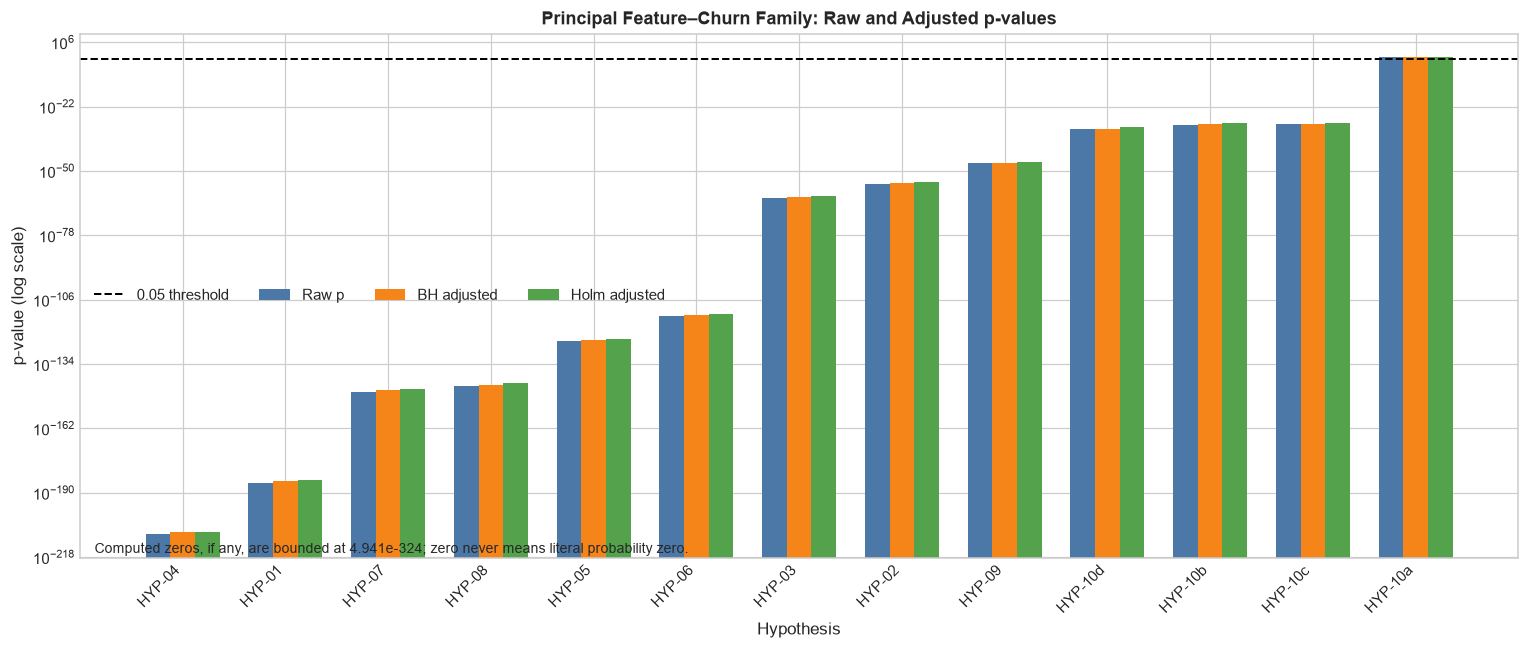

In [9]:
# ruff: noqa: E501
changed_bh = principal_results.loc[principal_results["preliminary_unadjusted_decision"] != principal_results["bh_fdr_decision"], "hypothesis_id"].tolist()
changed_holm = principal_results.loc[principal_results["preliminary_unadjusted_decision"] != principal_results["holm_fwer_decision"], "hypothesis_id"].tolist()
all_primary = corrected_results.loc[corrected_results["designation"].eq("Primary")]
all_changed_bh = all_primary.loc[all_primary["preliminary_unadjusted_decision"] != all_primary["bh_fdr_decision"], ["hypothesis_id", "multiple_testing_family"]]
all_changed_holm = all_primary.loc[all_primary["preliminary_unadjusted_decision"] != all_primary["holm_fwer_decision"], ["hypothesis_id", "multiple_testing_family"]]
print("Principal-family changes under BH:", changed_bh or "None")
print("Principal-family changes under Holm:", changed_holm or "None")
display(Markdown("### All primary-test decision changes\n\n**BH:** " + (", ".join(all_changed_bh["hypothesis_id"]) if len(all_changed_bh) else "None") + "  \n**Holm:** " + (", ".join(all_changed_holm["hypothesis_id"]) if len(all_changed_holm) else "None")))

plot_table = principal_results.sort_values("raw_p_value").reset_index(drop=True)
x = np.arange(len(plot_table)); width = 0.24
fig, axis = plt.subplots(figsize=(14, 6))
for offset, column, label, color in [(-width, "raw_p_value", "Raw p", "#4C78A8"), (0, "bh_adjusted_p_value", "BH adjusted", "#F58518"), (width, "holm_adjusted_p_value", "Holm adjusted", "#54A24B")]:
    axis.bar(x + offset, np.maximum(plot_table[column].to_numpy(float), smallest_positive), width, label=label, color=color)
axis.axhline(alpha, color="black", linestyle="--", linewidth=1.3, label="0.05 threshold")
axis.set_yscale("log")
axis.set_xticks(x, plot_table["hypothesis_id"], rotation=45, ha="right")
axis.set(title="Principal Feature–Churn Family: Raw and Adjusted p-values", xlabel="Hypothesis", ylabel="p-value (log scale)")
axis.legend(ncol=4)
axis.text(0.01, 0.01, f"Computed zeros, if any, are bounded at {smallest_positive:.3e}; zero never means literal probability zero.", transform=axis.transAxes, fontsize=9)
fig.tight_layout()
plt.show()

## 10. Interpretation, modelling implications, and limitations

- Correction asks whether evidence survives a declared search, while effect size asks how large the marginal relationship appears. A corrected rejection can still have negligible operational value; a non-rejection can still leave uncertainty about an important effect.
- Statistical evidence is not feature importance. Predictive usefulness depends on incremental out-of-sample performance, interactions, redundancy, calibration, stability, leakage risk, availability at decision time, and cost. No predictor is removed solely because a null is not rejected.
- The strong predictor-dependency results warn that marginal feature–churn associations may be confounded or redundant in a model. They motivate later multicollinearity and conditional modelling work, but that work is intentionally out of scope.
- These are observational, marginal, EDA-informed results from a dataset with an undocumented sampling mechanism. Adjustment does not turn them into causal effects or independent confirmation. Hidden clustering, temporal dependence, measurement error, and dataset shift remain possible.
- BH's standard guarantee relies on independence or suitable positive dependence. Structural relationships among contract, tenure, service, charges, and billing make Holm an important arbitrary-dependence sensitivity check.
- Cohen's $d$, Cliff's $\delta$, corrected Cramér's $V$, and rank $\epsilon^2$ answer different questions. Their magnitudes are not directly interchangeable.

## 11. Interview questions with speakable answers

### 1. Why is multiple hypothesis testing correction required?

Every test creates a chance of a false positive. When I inspect many hypotheses, the chance of at least one chance finding rises. Correction calibrates decisions to the whole pre-defined family rather than pretending each test was the only one run.

### 2. What is the difference between FWER and FDR?

FWER controls the probability of making even one false rejection in a family, so it is stringent. FDR controls the expected proportion of false discoveries among all discoveries, which usually gives more power in exploratory screening.

### 3. When would you prefer Benjamini–Hochberg over Holm or Bonferroni?

I prefer BH when the goal is exploratory discovery across many hypotheses and I can tolerate a controlled fraction of false discoveries. I prefer Holm when any false positive is costly or dependence is uncertain; Holm is uniformly at least as powerful as basic Bonferroni while controlling FWER.

### 4. Why should statistically significant features not automatically be selected?

A marginal p-value is not incremental predictive value. A feature can be statistically significant yet redundant, unstable, unavailable at scoring time, ethically unsuitable, or too small to matter. Selection should use domain constraints and leakage-safe out-of-sample modelling, not p-values alone.

## 12. Integrity, leakage, and reproducibility verification

The final cell verifies family counts, adjusted-value properties, directions and effect bounds, all thirteen prior notebook checksums, the development checksum, and development-only loading. It also confirms that Games–Howell is absent from the broad register.

In [10]:
# ruff: noqa: E501
assert corrected_results["bh_adjusted_p_value"].between(0, 1).all()
assert corrected_results["holm_adjusted_p_value"].between(0, 1).all()
assert (corrected_results["bh_adjusted_p_value"] + 1e-15 >= corrected_results["p_value_used_for_adjustment"]).all()
assert (corrected_results["holm_adjusted_p_value"] + 1e-15 >= corrected_results["p_value_used_for_adjustment"]).all()
assert effect_size_consolidation.loc[effect_size_consolidation["effect_size_measure"].str.contains("Cohen"), "effect_size"].between(-np.inf, np.inf).all()
assert effect_size_consolidation.loc[effect_size_consolidation["effect_size_measure"].str.contains("Cliff"), "effect_size"].between(-1, 1).all()
assert effect_size_consolidation.loc[effect_size_consolidation["effect_size_measure"].str.contains("Cramér"), "effect_size"].between(0, 1).all()
assert effect_size_consolidation.loc[effect_size_consolidation["effect_size_measure"].str.contains("epsilon"), "effect_size"].between(0, 1).all()
assert not hypothesis_register["statistical_test"].str.contains("Games", case=False).any()
assert list(numerical_specs) == ["HYP-01", "HYP-02", "HYP-03"]
assert list(categorical_specs) == ["HYP-04", "HYP-05", "HYP-06", "HYP-07", "HYP-08", "HYP-09", "HYP-10a", "HYP-10b", "HYP-10c", "HYP-10d"]
assert list(multiple_group_specs) == ["HYP-11", "HYP-12", "HYP-13"]

expected_previous_hashes = {
    "01_exploratory_data_analysis.ipynb": "970288d8018d13770f972835b4ecc86fe7857e28c0b7447b104fa5b3edcf662b",
    "02_univariate_analysis.ipynb": "0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8edef76e26d61b851de4a",
    "03_bivariate_analysis.ipynb": "1ec80ddc2eb412b604841a20afa78e5199903ff00206f4e291a48a16d655d495",
    "04_multivariate_analysis.ipynb": "4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0ff01afbe3d596573331",
    "05_correlation_association_analysis.ipynb": "e787e951b3443c6052d960b384d5418c7c13e2e846c6d7e3a15f7895cd7faa13",
    "06_outlier_anomaly_analysis.ipynb": "f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece57da2f74d9eb3e1ef4b",
    "07_customer_segmentation_business_analysis.ipynb": "1dee5509dc803187d99bb61af9d2eefc272f8a83c9d1014409f35834ca35cf6d",
    "08_statistical_foundations.ipynb": "11578c2e7cfa07a3fb826601d7afb356c224443d6547f7dc93725b45ac6653f2",
    "09_confidence_interval_analysis.ipynb": "50bf2497adec4d4e5d09502b0849420c9e53d5383615152f51fbc71629fb61c3",
    "10_distribution_diagnostics.ipynb": "38341766a6a26f1c7ba03c521500d15eef0038efd9e01d7b6bf7468de0dd1b58",
    "11_numerical_hypothesis_testing.ipynb": "fe98c6d2591d9f87dd256ae9a37a32004e194297f8dc01ce44abc6bff6501662",
    "12_categorical_hypothesis_testing.ipynb": "4d6cd50439617c88f1f0452961c56d0069877fa3352436bccc2aa35fa3f53389",
    "13_multiple_group_comparisons.ipynb": "1b2deba08ddcc68f3e2d6945aa657305ec04c6bae59b7c1c05912f026a18cf77",
}
observed_previous_hashes = {name: hashlib.sha256((PROJECT_ROOT / "notebooks" / name).read_bytes()).hexdigest() for name in expected_previous_hashes}
source_sha256_after = hashlib.sha256(development_path.read_bytes()).hexdigest()

assert observed_previous_hashes == expected_previous_hashes
assert source_sha256_before == source_sha256_after == "28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13"
assert development_path != (PROJECT_ROOT / config["data"]["test_path"]).resolve()
assert development_path != (PROJECT_ROOT / config["data"]["validated_path"]).resolve()
assert random_state == 42 and alpha == q == 0.05

print("All multiplicity, effect-size, integrity, and leakage checks passed.")
print("Loaded data source:", development_path.relative_to(PROJECT_ROOT))
print("Held-out test and complete validated datasets were not accessed.")
display(pd.DataFrame({"expected_sha256": expected_previous_hashes, "observed_sha256": observed_previous_hashes}))

All multiplicity, effect-size, integrity, and leakage checks passed.
Loaded data source: data/processed/development.parquet
Held-out test and complete validated datasets were not accessed.


,expected_sha256,observed_sha256
01_exploratory_data_analysis.ipynb,970288d8018d13770f972835b4ecc86fe7857e28c0b744...,970288d8018d13770f972835b4ecc86fe7857e28c0b744...
02_univariate_analysis.ipynb,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...
03_bivariate_analysis.ipynb,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...
04_multivariate_analysis.ipynb,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...
05_correlation_association_analysis.ipynb,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...
06_outlier_anomaly_analysis.ipynb,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...
07_customer_segmentation_business_analysis.ipynb,1dee5509dc803187d99bb61af9d2eefc272f8a83c9d101...,1dee5509dc803187d99bb61af9d2eefc272f8a83c9d101...
08_statistical_foundations.ipynb,11578c2e7cfa07a3fb826601d7afb356c224443d6547f7...,11578c2e7cfa07a3fb826601d7afb356c224443d6547f7...
09_confidence_interval_analysis.ipynb,50bf2497adec4d4e5d09502b0849420c9e53d538361515...,50bf2497adec4d4e5d09502b0849420c9e53d538361515...
10_distribution_diagnostics.ipynb,38341766a6a26f1c7ba03c521500d15eef0038efd9e01d...,38341766a6a26f1c7ba03c521500d15eef0038efd9e01d...
